In [4]:
library(tidyverse)
library(DESeq2)
library(tximport)
library(rtracklayer)
library(RColorBrewer)
library(ggrepel)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’

In [2]:
dir <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/HepG2"

files <- list.files(dir, pattern="genes.results", full.name=TRUE)
files

[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/HepG2/rep1_brm_1_anno_rsem.genes.results" 
[2] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/HepG2/rep1_brm_2_anno_rsem.genes.results" 
[3] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/HepG2/rep1_dmso_1_anno_rsem.genes.results"
[4] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/HepG2/rep1_dmso_2_anno_rsem.genes.results"

In [5]:
#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz"
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed", header=F, sep='\t')

In [6]:
#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

In [7]:
#make coldata
col.data <- data.frame(Condition=c("BRM", "BRM", "DMSO", "DMSO"),
              Replicate=c(1,2,1,2))

In [8]:
#read in RSEM data
txi <- tximport(files=files, type="rsem", txIn=FALSE, txOut=FALSE)


reading in files with read_tsv

1 
2 
3 
4 




In [9]:
#filter txi object
nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 78724

[1] 14214

[1] 14214

[1] 14214

In [16]:
dds <- DESeqDataSetFromTximport(txi=txi, colData=col.data, design = ~Condition)
des <- DESeq(dds)
res <- results(des, contrast=c("Condition", "BRM", "DMSO"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



using 'avgTxLength' from assays(dds), correcting for library size

Coordinate system already present. Adding new coordinate system, which will
replace the existing one.


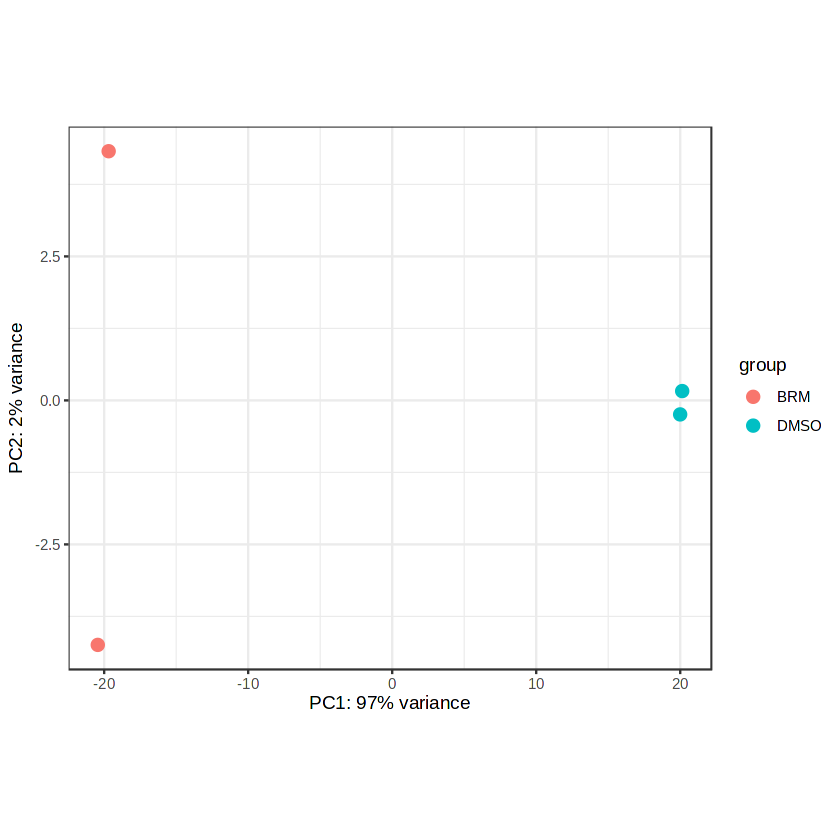

In [11]:
vsd <- vst(dds, blind=TRUE)
plotPCA(vsd, intgroup="Condition") + theme_bw() + coord_fixed(ratio=4)

In [13]:
volcano <- function(table, rowdat, q_thresh=0.05, fc_thresh=log2(1.5), main=""){
    temp <- table %>% mutate(gene=rowdat$gene_name) %>% 
            na.omit() %>%
            mutate(change = case_when(log2FoldChange > fc_thresh & 
                                      padj < q_thresh ~ "up", 
                                      log2FoldChange < -fc_thresh & padj < q_thresh ~ "down", 
                                      TRUE ~ "ns"))
    xmax <- max(abs(temp$log2FoldChange))
    n_down <- table(temp$change)[1]
    n_up <- table(temp$change)[3]
    
    ggplot(temp, aes(color=change, x=log2FoldChange,y=-log10(padj))) +
        geom_point() +
        geom_vline(xintercept=c(-fc_thresh, fc_thresh), linetype=2) + 
        geom_hline(yintercept=-log10(q_thresh), linetype=2) + 
        xlim(-xmax, xmax) +
        scale_color_manual(values=c("down"=brewer.pal(3,"Paired")[2], "ns"="grey", "up"=brewer.pal(6,"Paired")[6])) +
        geom_text_repel(data=temp[temp$change!="ns",], aes(label=gene), size=3) +
        ggtitle(main, subtitle=paste("Down:", n_down, "; Up:", n_up)) +
        ylim(0,100)
}

Warning message:
“Removed 17 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 17 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message:
“ggrepel: 2482 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


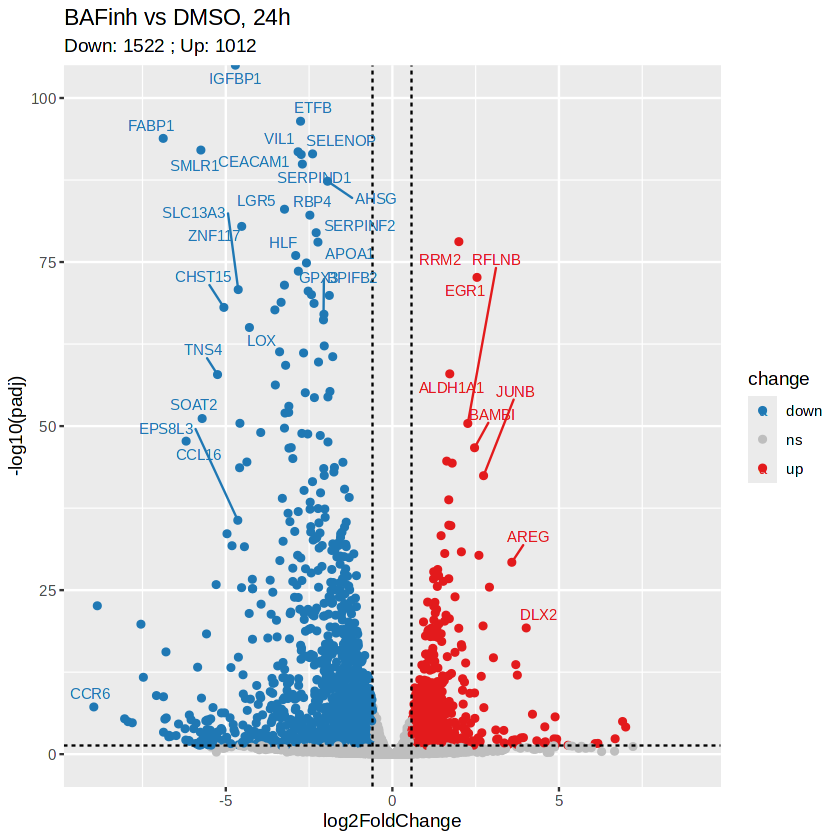

In [19]:
volcano(data.frame(res), row.data,main="BAFinh vs DMSO, 24h")

In [20]:
res <- res %>% data.frame() %>% mutate(gene=row.data$gene_name,
                                       change=case_when(log2FoldChange < -log2(1.5) & padj < .05 ~ "down", 
                                                   log2FoldChange > log2(1.5) & padj < .05 ~ "up",
                                                   TRUE ~ "ns")) %>% na.omit()
summary(res)

    baseMean         log2FoldChange          lfcSE              stat          
 Min.   :     3.57   Min.   :-8.961163   Min.   :0.09102   Min.   :-42.96071  
 1st Qu.:    72.79   1st Qu.:-0.419214   1st Qu.:0.18086   1st Qu.: -1.26937  
 Median :   270.01   Median :-0.002859   Median :0.25785   Median : -0.00754  
 Mean   :   749.67   Mean   :-0.137842   Mean   :0.42606   Mean   : -0.28192  
 3rd Qu.:   668.87   3rd Qu.: 0.350086   3rd Qu.:0.47023   3rd Qu.:  1.19131  
 Max.   :141412.85   Max.   : 7.221989   Max.   :4.84117   Max.   : 26.39340  
     pvalue             padj             gene              change         
 Min.   :0.00000   Min.   :0.00000   Length:13385       Length:13385      
 1st Qu.:0.01533   1st Qu.:0.06131   Class :character   Class :character  
 Median :0.22019   Median :0.44035   Mode  :character   Mode  :character  
 Mean   :0.31990   Mean   :0.43995                                        
 3rd Qu.:0.57805   3rd Qu.:0.77072                                      

In [21]:
write.table(res, "BRM_24h_DEGs.tsv", sep='\t', row.names=FALSE, quote=FALSE)